# Paso 1: Crear Variables de Continuidad Acumulativa

In [1]:
import pandas as pd

# Lee el archivo CSV especificando una codificación alternativa
data = pd.read_csv("../data/base.csv", encoding='latin1')

# Convertir las columnas de matrícula a booleano para evitar errores
data['mat_20_2'] = data['2020-2'].astype(bool)
data['mat_21_1'] = data['2021-1'].astype(bool)
data['mat_21_2'] = data['2021-2'].astype(bool)

# Crear variables de continuidad acumulativa usando &
data['continuidad_1'] = data['2020-2']  # Continuidad en 2020-2
data['continuidad_2'] = data['2020-2'] & data['2021-1']  # Continuidad en 2020-2 y 2021-1
data['continuidad_3'] = data['2020-2'] & data['2021-1'] & data['2021-2']  # Continuidad en los tres semestres

# Convertir las columnas de continuidad acumulativa a 0 y 1 (si es necesario)
data['continuidad_1'] = data['continuidad_1'].astype(int)
data['continuidad_2'] = data['continuidad_2'].astype(int)
data['continuidad_3'] = data['continuidad_3'].astype(int)

# Verifica los resultados
print(data[['2020-2', '2021-1', '2021-2', 'continuidad_1', 'continuidad_2', 'continuidad_3']].head())


   2020-2  2021-1  2021-2  continuidad_1  continuidad_2  continuidad_3
0       0       1       1              0              0              0
1       1       1       1              1              1              1
2       1       1       1              1              1              1
3       1       1       1              1              1              1
4       1       1       1              1              1              1


# Paso 2: Definir la Variable Puntaje_RD y las Covariables

In [2]:
print(data.columns)

Index(['NÂ°', 'DNI', 'APELLIDOS Y NOMBRES', 'REGIÃN DE ESTUDIO', 'IES',
       'SEDE', 'CARRERA', 'PUNTAJE FINAL', 'CONDICIÃN', 'RESTRICCION ',
       '2020-2', '2021-1', '2021-2', 'edad', 'sexo', 'codigo_ubigeo',
       'departamento', 'provincia', 'distrito', 'periodo_ingreso',
       'domicilio_departamento', 'domicilio_distrito', 'carrera', 'TOP ',
       'Familia', 'mat_20_2', 'mat_21_1', 'mat_21_2', 'continuidad_1',
       'continuidad_2', 'continuidad_3'],
      dtype='object')


In [3]:
data.sexo

0        FEMENINO
1        FEMENINO
2        FEMENINO
3       MASCULINO
4        FEMENINO
          ...    
7045     FEMENINO
7046     FEMENINO
7047    MASCULINO
7048     FEMENINO
7049     FEMENINO
Name: sexo, Length: 7050, dtype: object

In [4]:
import random

# Crear variables de tratamiento y de corte como antes
data['D'] = data['CONDICIÃN'].apply(lambda x: 1 if x == 'SELECCIONADO' else 0)
data['Z'] = data['PUNTAJE FINAL'].apply(lambda x: 1 if x >= 60 else 0)

# Crear columna 'ALEA' para aleatoriedad
data['ALEA'] = [random.randint(0, 500)/100 for _ in range(len(data))]
# Crear columna 'ALEA' con valores aleatorios entre 0 y 2.5
#data['ALEA'] = [random.uniform(0, 2.5) for _ in range(len(data))]

# Función para calcular Puntaje_RD
def calcular_puntaje(row):
    if row['PUNTAJE FINAL'] == 60:
        if row['CONDICIÃN'] == 'NO SELECCIONADO':
            return row['PUNTAJE FINAL'] - row['ALEA']
        elif row['CONDICIÃN'] == 'SELECCIONADO':
            return row['PUNTAJE FINAL'] + row['ALEA']
    else:
        return row['PUNTAJE FINAL'] + row['ALEA'] if random.choice([True, False]) else row['PUNTAJE FINAL'] - row['ALEA']

# Aplica la función a cada fila
data['Puntaje_RD'] = data.apply(calcular_puntaje, axis=1)

# Crear variables dummy para las instituciones educativas
#covars = pd.get_dummies(data['IES']).astype(int).iloc[:, 1:]

# Convertir IES en variables dummy como covariables
covariates = pd.get_dummies(data['IES'], drop_first=True).astype(int)

data


,NÂ°,DNI,APELLIDOS Y NOMBRES,REGIÃN DE ESTUDIO,IES,SEDE,CARRERA,PUNTAJE FINAL,CONDICIÃN,RESTRICCION,...,mat_20_2,mat_21_1,mat_21_2,continuidad_1,continuidad_2,continuidad_3,D,Z,ALEA,Puntaje_RD
0,2,70801736,"ABAD GARCIA, MARISOL",LIMA\nMETROPOLITANA,UNIVERSIDAD PRIVADA DEL NORTE,SEDE COMAS,ADMINISTRACION Y NEGOCIOS INTERNACIONALES,55,NO SELECCIONADO,LIMA,...,False,True,True,0,0,0,0,0,4.62,50.38
1,3,71469634,"ABAD MARINA, ROCIO DEL PILAR",LIMA\nMETROPOLITANA,UNIVERSIDAD ANTONIO RUIZ DE MONTOYA,SEDE PUEBLO LIBRE,DERECHO (4),60,NO SELECCIONADO,LIMA,...,True,True,True,1,1,1,0,1,4.26,55.74
2,6,60736859,"ABAD VASQUEZ, DAYANA ANTUANET",LIMA\nMETROPOLITANA,UNIVERSIDAD PRIVADA DEL NORTE,SEDE LOS OLIVOS,ADMINISTRACION,50,NO SELECCIONADO,LIMA,...,True,True,True,1,1,1,0,0,3.57,46.43
3,7,71332025,"ABAD VELIZ, JOSE FRANCISCO",LIMA\nMETROPOLITANA,UNIVERSIDAD TECNOLOGICA DEL PERU - UTP,SEDE VILLA EL SALVADOR,DERECHO (4),50,NO SELECCIONADO,LIMA,...,True,True,True,1,1,1,0,0,4.87,45.13
4,8,74855443,"ABAD CHATE, JIREH ANGELICA ARELY",LIMA\nMETROPOLITANA,UNIVERSIDAD PRIVADA SAN IGNACIO DE LOYOLA,SEDE LA MOLINA,ARTE Y DISEÃâO EMPRESARIAL,70,SELECCIONADO,LIMA,...,True,True,True,1,1,1,1,1,1.96,68.04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7045,13097,75825475,"AGUILAR CERNA, NINFA GRACE\n",LIMA\nMETROPOLITANA,UNIVERSIDAD TECNOLOGICA DEL PERU - UTP\nNABEC,SEDE LOS OLIVOS\n,PSICOLOGIA\n,50,NO SELECCIONADO,LIMA,...,True,True,True,1,1,1,0,0,0.92,49.08
7046,13098,76825449,"CABOS LINARES, DIANA LIZETH\n",LIMA\nMETROPOLITANA,UNIVERSIDAD CESAR VALLEJO,SEDE ATE\n,DERECHO (4),50,NO SELECCIONADO,LIMA,...,True,True,True,1,1,1,0,0,1.31,48.69
7047,13099,40288773,"CHUMBIRIZA GONZALES, CARLOS\n",LIMA\nMETROPOLITANA,UNIVERSIDAD AUTONOMA DEL PERU,SEDE VILLA EL SALVADOR\n,PSICOLOGIA\n,55,NO SELECCIONADO,LIMA,...,True,True,True,1,1,1,0,0,0.44,54.56
7048,13100,75886632,"GONZALES GARCIA, ANGIE KARLA\n",LIMA\nMETROPOLITANA,UNIVERSIDAD ANTONIO RUIZ DE MONTOYA,SEDE PUEBLO LIBRE\n,DERECHO (4),60,NO SELECCIONADO,LIMA,...,True,True,True,1,1,1,0,1,2.56,57.44


In [5]:
# Obtener el valor mínimo y máximo de la columna 'ALEA'
min_alea = data['ALEA'].min()
max_alea = data['ALEA'].max()

print("Puntaje mínimo de ALEA:", min_alea)
print("Puntaje máximo de ALEA:", max_alea)

Puntaje mínimo de ALEA: 0.0
Puntaje máximo de ALEA: 5.0


# Paso 3: Ejecutar la Regresión Discontinua Fuzzy con covariables

In [9]:
from rdrobust import rdrobust
import numpy as np

# Crear variable dicotómica para TOP: 1 = TOP 30, 0 = NO TOP 30
data['TOP_dicotomica'] = data['TOP '].apply(lambda x: 1 if x == 'TOP 30' else 0)
df = data.copy()

# Crear variable sexo_bin (0 = mujer, 1 = hombre)
df['sexo_str'] = df['sexo'].astype(str).str.strip().str.upper()

data['sexo_bin'] = data['sexo'].astype(str).str.strip().str.upper().map(
    lambda x: 1 if x in ['M','MASCULINO'] else 0
)

# Selección de covariables
covariates = data[['TOP_dicotomica','edad','sexo_bin']]


# Diccionario para almacenar resultados
results_acumulativa = {}

# Variables de continuidad acumulada
continuidad_acumulada = {
    'continuidad_1': data['continuidad_1'],
    'continuidad_2': data['continuidad_2'],
    'continuidad_3': data['continuidad_3']
}

# Ejecutar rdrobust para cada nivel de continuidad
for nivel, y in continuidad_acumulada.items():
    score = data['Puntaje_RD']
    est = rdrobust(
        y=y,
        x=score,
        c=60,
        fuzzy=data['D'],
        covs=covariates.values,
        all=True
    )
    results_acumulativa[nivel] = est
    print(f"Resultados para {nivel}")
    print(est)

Mass points detected in the running variable.
Mass points detected in the running variable.
Resultados para continuidad_1
Call: rdrobust
Number of Observations:                  6905
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                    mserd
Var-Cov Estimator:                         NN

                                Left      Right
------------------------------------------------
Number of Observations          1883       5022
Number of Unique Obs.           1043       2221
Number of Effective Obs.         904       1456
Bandwidth Estimation           5.367      5.367
Bandwidth Bias                 8.846      8.846
rho (h/b)                      0.607      0.607

Method             Coef.     S.E.   t-stat    P>|t|       95% CI      
-------------------------------------------------------------------------
Conventional        0.13    0.027    4.728   2.265e-06 

In [10]:
# Paso 4: Ejecutar la Regresión Discontinua Fuzzy sin covariables

In [11]:
# Ejecutar rdrobust para cada nivel de continuidad
for nivel, y in continuidad_acumulada.items():
    score = data['Puntaje_RD']
    est = rdrobust(
        y=y,
        x=score,
        c=60,
        fuzzy=data['D'],
        all=True
    )
    results_acumulativa[nivel] = est
    print(f"Resultados para {nivel}")
    print(est)

Mass points detected in the running variable.
Mass points detected in the running variable.
Resultados para continuidad_1
Call: rdrobust
Number of Observations:                  7050
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                    mserd
Var-Cov Estimator:                         NN

                                Left      Right
------------------------------------------------
Number of Observations          1997       5053
Number of Unique Obs.           1076       2225
Number of Effective Obs.         973       1511
Bandwidth Estimation           5.571      5.571
Bandwidth Bias                 8.836      8.836
rho (h/b)                      0.631      0.631

Method             Coef.     S.E.   t-stat    P>|t|       95% CI      
-------------------------------------------------------------------------
Conventional       0.163     0.03    5.421   5.938e-08 

# Paso 5: Gráficos de Discontinuidad para Cada Nivel de Continuidad

Mass points detected in the running variable.


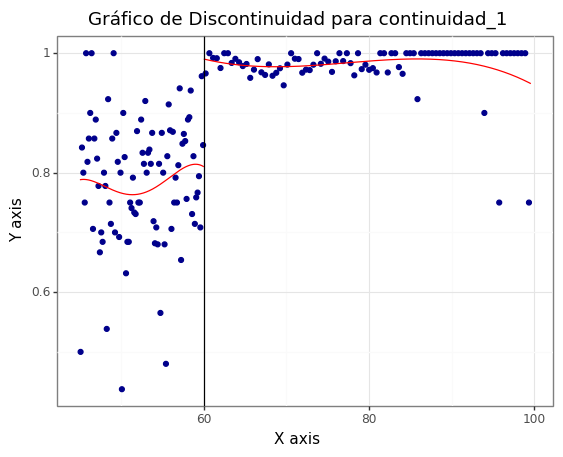


Mass points detected in the running variable.


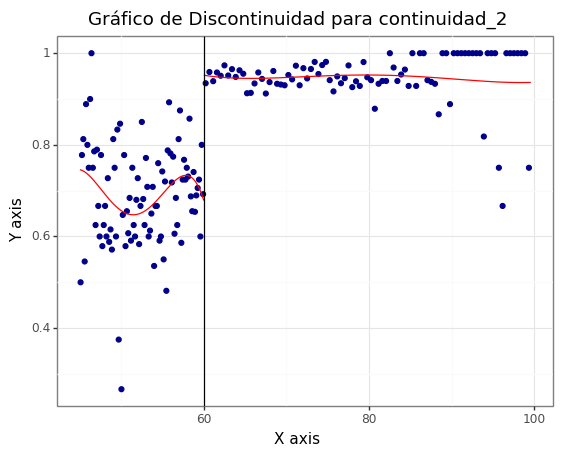


Mass points detected in the running variable.


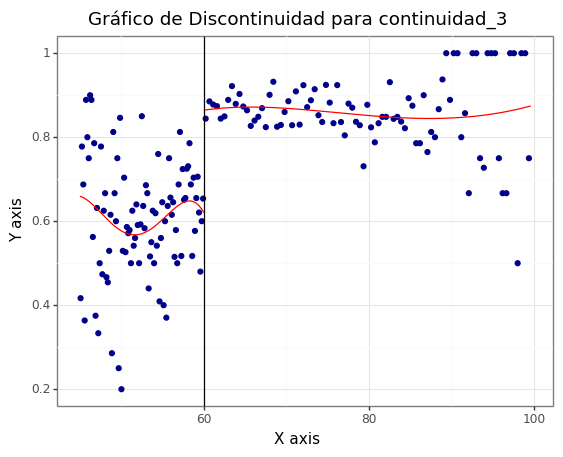

In [12]:
from rdrobust import rdplot

for nivel, y in continuidad_acumulada.items():
    rdplot(y=y, x=score, c=60, title=f"Gráfico de Discontinuidad para {nivel}")


In [13]:
# Crear DataFrame de resultados para reportar
summary = {
    'Semestre': [],
    'Coef': [],
    'SE': [],
    't-stat': [],
    'p-value': [],
    'CI Lower': [],
    'CI Upper': []
}

# Extraer datos del análisis para cada semestre
for nivel, res in results_acumulativa.items():
    summary['Semestre'].append(nivel)
    
    # Determinar el método a usar ('Robust' preferiblemente, 'Conventional' en su defecto)
    if 'Robust' in res.coef.index:
        metodo = 'Robust'
    elif 'Conventional' in res.coef.index:
        metodo = 'Conventional'
    else:
        metodo = res.coef.index[0]  # Usar el primer método disponible si ninguno es 'Robust' o 'Conventional'
    
    # Extraer los valores correspondientes
    coef = res.coef.loc[metodo, 'Coeff']
    se = res.se.loc[metodo, 'Std. Err.']
    t_stat = res.t.loc[metodo, 't-stat.']
    p_value = res.pv.loc[metodo, 'P>|t|']
    ci_lower = res.ci.loc[metodo, 'CI Lower']
    ci_upper = res.ci.loc[metodo, 'CI Upper']
    
    # Agregar los valores al resumen
    summary['Coef'].append(coef)
    summary['SE'].append(se)
    summary['t-stat'].append(t_stat)
    summary['p-value'].append(p_value)
    summary['CI Lower'].append(ci_lower)
    summary['CI Upper'].append(ci_upper)

# Convertir a DataFrame
summary_df = pd.DataFrame(summary)
print(summary_df)


        Semestre      Coef        SE    t-stat       p-value  CI Lower  \
0  continuidad_1  0.155640  0.035636  4.367434  1.257150e-05  0.085794   
1  continuidad_2  0.248433  0.048231  5.150876  2.592724e-07  0.153902   
2  continuidad_3  0.275747  0.062152  4.436660  9.136550e-06  0.153932   

   CI Upper  
0  0.225486  
1  0.342965  
2  0.397563  


# Gráfico Comparativo de Continuidad Académica

In [14]:
import matplotlib.pyplot as plt

# Calcular promedios de continuidad para el grupo de beneficiarios y no beneficiarios en cada nivel
# Para los beneficiarios (Puntaje_RD >= 60)
beneficiarios = data[data['Puntaje_RD'] >= 60]
promedio_cont_beneficiarios = [
    beneficiarios['continuidad_1'].mean() * 100,
    beneficiarios['continuidad_2'].mean() * 100,
    beneficiarios['continuidad_3'].mean() * 100
]

# Para los no beneficiarios (Puntaje_RD < 60)
no_beneficiarios = data[data['Puntaje_RD'] < 60]
promedio_cont_no_beneficiarios = [
    no_beneficiarios['continuidad_1'].mean() * 100,
    no_beneficiarios['continuidad_2'].mean() * 100,
    no_beneficiarios['continuidad_3'].mean() * 100
]

# Nombres para los niveles de continuidad
niveles_continuidad = ['1 semestre', '2 semestres', '3 semestres']


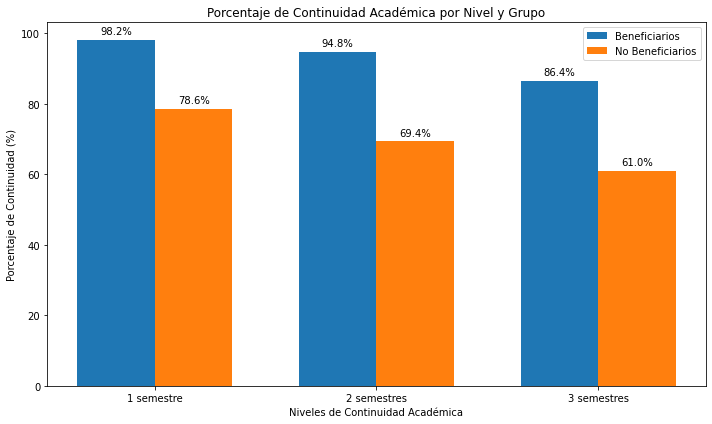

In [15]:
# Configuración del gráfico
fig, ax = plt.subplots(figsize=(10, 6))

# Ancho de las barras
bar_width = 0.35
index = range(len(niveles_continuidad))

# Crear las barras para cada grupo
bar1 = ax.bar(index, promedio_cont_beneficiarios, bar_width, label='Beneficiarios')
bar2 = ax.bar([i + bar_width for i in index], promedio_cont_no_beneficiarios, bar_width, label='No Beneficiarios')

# Etiquetas y título
ax.set_xlabel('Niveles de Continuidad Académica')
ax.set_ylabel('Porcentaje de Continuidad (%)')
ax.set_title('Porcentaje de Continuidad Académica por Nivel y Grupo')
ax.set_xticks([i + bar_width / 2 for i in index])
ax.set_xticklabels(niveles_continuidad)
ax.legend()

# Añadir etiquetas de porcentaje encima de las barras
for bar in bar1 + bar2:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, yval + 1, f'{yval:.1f}%', ha='center', va='bottom')

# Mostrar el gráfico
plt.tight_layout()
plt.show()


# Donut RD (sensibilidad excluyendo vecindad inmediata)

In [16]:
continuidades = ['continuidad_1','continuidad_2','continuidad_3']
corte = 60.0
c = corte
# Covariables recomendadas
cov_basicas = []
if 'edad' in data.columns: cov_basicas.append('edad')
if 'sexo' in data.columns:  # conviértelo en 0/1 antes si no lo está
    data['sexo_bin'] = (data['sexo'].astype(str).str[0].str.upper().isin(['M','H','1'])).astype(int)
    cov_basicas.append('sexo_bin')
if 'calidad_ies' in data.columns: cov_basicas.append('calidad_ies')
# Dummies IES (opcional; si muchas IES, considera omitir o usar efectos fijos en IV2SLS)
ies_dum = pd.get_dummies(data['IES'], drop_first=True, dtype=int)
covs = pd.concat([data[cov] for cov in cov_basicas], axis=1)
# covs = pd.concat([covs, ies_dum], axis=1)  # si decides incluir

def donut_mask(x, c, hole=0.25):  # excluye ±0.25 puntos alrededor del corte
    return (x < c - hole) | (x > c + hole)

for y in continuidades:
    m = donut_mask(data['Puntaje_RD'], corte, hole=0.25)
    est_donut = rdrobust(
        y = data.loc[m, y].to_numpy(),
        x = data.loc[m, 'Puntaje_RD'].to_numpy(),
        c = corte,
        fuzzy = data.loc[m, 'D'].to_numpy(),
        covs = (covs.loc[m].to_numpy() if not covs.empty else None),
        all = True
    )
    print(f"\n--- DONUT RD (±0.25) para {y} ---")
    print(est_donut)


Mass points detected in the running variable.
Mass points detected in the running variable.

--- DONUT RD (±0.25) para continuidad_1 ---
Call: rdrobust
Number of Observations:                  6794
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                    mserd
Var-Cov Estimator:                         NN

                                Left      Right
------------------------------------------------
Number of Observations          1843       4951
Number of Unique Obs.           1025       2197
Number of Effective Obs.         719       1114
Bandwidth Estimation            4.39       4.39
Bandwidth Bias                 7.451      7.451
rho (h/b)                      0.589      0.589

Method             Coef.     S.E.   t-stat    P>|t|       95% CI      
-------------------------------------------------------------------------
Conventional       0.172    0.037    4.7

# Balance de covariable 

In [17]:
# Ventana simétrica simple para balance (±h)
h = 10
mask = (data['Puntaje_RD'] >= corte - h) & (data['Puntaje_RD'] <= corte + h)
sub = data.loc[mask].copy()
sub['xc'] = sub['Puntaje_RD'] - corte
sub['Z'] = (sub['Puntaje_RD'] >= corte).astype(int)
w = (1 - (sub['xc'].abs()/h)).clip(lower=0)  # kernel triangular

import statsmodels.api as sm
import numpy as np

def test_balance(var):
    df = sub.dropna(subset=[var]).copy()
    X = sm.add_constant(np.c_[df['Z'], df['xc'], df['Z']*df['xc']])
    y = df[var].to_numpy()
    mod = sm.WLS(y, X, weights=w.loc[df.index]).fit(cov_type='HC1')
    coefZ, seZ, pZ = mod.params[1], mod.bse[1], mod.pvalues[1]
    lo = coefZ - 1.96*seZ; hi = coefZ + 1.96*seZ
    return coefZ, seZ, pZ, lo, hi, int(mod.nobs)

covs_balance = ['edad','sexo_bin','TOP_dicotomica'] 
rows = []
for v in covs_balance:
    if v in sub.columns:
        rows.append((v,)+test_balance(v))
balance_df = pd.DataFrame(rows, columns=['covariable','coef_Z','se','p','ci_lo','ci_hi','n'])
balance_df.to_csv("tabla_balance_covariables.csv", index=False)
print(balance_df)


       covariable    coef_Z        se         p     ci_lo     ci_hi     n
0            edad -0.396270  0.280433  0.157637 -0.945918  0.153379  4115
1        sexo_bin -0.007688  0.031615  0.807882 -0.069654  0.054278  4218
2  TOP_dicotomica  0.023075  0.016878  0.171563 -0.010005  0.056155  4218


# Sensibilidad a bandwidth 

In [18]:
bandas = [3, 5, 7.5, 10, 12.5]
sens_rows = []

for y in continuidades:
    for h in bandas:
        m = (data['Puntaje_RD'] >= corte - h) & (data['Puntaje_RD'] <= corte + h)
        est_h = rdrobust(
            y = data.loc[m, y].to_numpy(),
            x = data.loc[m, 'Puntaje_RD'].to_numpy(),
            c = corte,
            fuzzy = data.loc[m, 'D'].to_numpy(),
            covs = covs.loc[m].to_numpy() if not covs.empty else None,
            all = True
        )
        # Toma el estimador robusto
        beta = est_h.coef.loc['Robust','Coeff']; se = est_h.se.loc['Robust','Std. Err.']
        sens_rows.append({'Y': y, 'h': h, 'beta': beta, 'se': se})

sens = pd.DataFrame(sens_rows)
sens.to_csv("tabla_rd_sensibilidad.csv", index=False)

# Plots
for y in continuidades:
    s = sens[sens['Y']==y].copy()
    if s.empty: continue
    plt.figure(figsize=(6,4))
    plt.errorbar(s['h'], s['beta'], yerr=1.96*s['se'], fmt='o-')
    plt.axhline(0, ls='--')
    plt.xlabel('Bandwidth (±h)')
    plt.ylabel('Efecto (pp)')
    plt.title(f"Sensibilidad del efecto – {y}")
    plt.tight_layout()
    plt.savefig(f"fig_sensibilidad_bandwidth_{y}.png", bbox_inches='tight')
    plt.close()
    
# Estimaciones con diferentes bandwidth
for h in [1, 2, 3, 4, 5]:
    est = rdrobust(y=data['continuidad_1'], x=data['Puntaje_RD'], c=60, h=h)
    print(f"h = {h}, Coef = {est.coef.loc['Robust','Coeff']:.3f}, p-val = {est.pv.loc['Robust','P>|t|']:.3f}")


Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the runnin

# Proxy McCrary con KDE + bootstrap


Densidad izq en 60: 0.04171227377537115
Densidad der en 60: 0.027126957458484157
Δ densidad (der - izq): -0.014585316316886993


C:\Users\lisbeth\AppData\Local\Temp\ipykernel_30420\2593229000.py:15: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
C:\Users\lisbeth\AppData\Local\Temp\ipykernel_30420\2593229000.py:16: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)


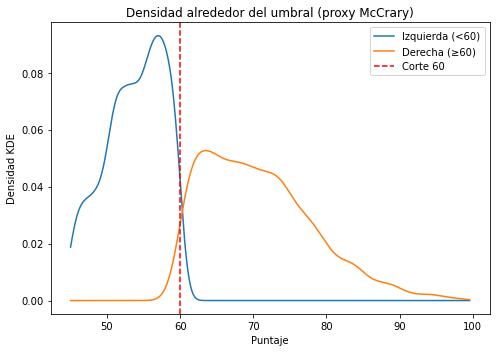

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.nonparametric.kde import KDEUnivariate

# running y corte
X = data['Puntaje_RD'].astype(float).to_numpy()
c = 60.0

X_left  = X[X < c]
X_right = X[X >= c]

kde_L = KDEUnivariate(X_left);  kde_L.fit(kernel="gau", bw="scott")
kde_R = KDEUnivariate(X_right); kde_R.fit(kernel="gau", bw="scott")

dens_L = float(kde_L.evaluate(c))
dens_R = float(kde_R.evaluate(c))
delta  = dens_R - dens_L
print("Densidad izq en 60:", dens_L)
print("Densidad der en 60:", dens_R)
print("Δ densidad (der - izq):", delta)

# gráfico
xs = np.linspace(X.min(), X.max(), 400)
plt.figure(figsize=(7,5))
plt.plot(xs, KDEUnivariate(X_left).fit(kernel="gau", bw="scott").evaluate(xs), label="Izquierda (<60)")
plt.plot(xs, KDEUnivariate(X_right).fit(kernel="gau", bw="scott").evaluate(xs), label="Derecha (≥60)")
plt.axvline(c, ls='--', color='red', label='Corte 60')
plt.xlabel("Puntaje"); plt.ylabel("Densidad KDE"); plt.title("Densidad alrededor del umbral (proxy McCrary)")
plt.legend(); plt.tight_layout(); plt.savefig("fig_proxy_mccrary.png", bbox_inches="tight"); plt.show()


In [20]:
import numpy as np

B = 1000  # puedes subir a 2000 si quieres más precisión
deltas = np.empty(B)
nL, nR = len(X_left), len(X_right)

rng = np.random.default_rng(123)

for b in range(B):
    boot_L = rng.choice(X_left,  nL, replace=True)
    boot_R = rng.choice(X_right, nR, replace=True)
    kdeL = KDEUnivariate(boot_L); kdeL.fit(kernel="gau", bw="scott")
    kdeR = KDEUnivariate(boot_R); kdeR.fit(kernel="gau", bw="scott")
    deltas[b] = float(kdeR.evaluate(c) - kdeL.evaluate(c))

ci_lo, ci_hi = np.percentile(deltas, [2.5, 97.5])
p_2cola = 2*min((deltas > 0).mean(), (deltas < 0).mean())

print(f"IC 95% para Δ densidad: [{ci_lo:.5f}, {ci_hi:.5f}]")
print(f"p-valor aprox. (bootstrap, 2 colas): {p_2cola:.4f}")


C:\Users\lisbeth\AppData\Local\Temp\ipykernel_30420\342252370.py:14: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)


IC 95% para Δ densidad: [-0.01987, -0.00986]
p-valor aprox. (bootstrap, 2 colas): 0.0000


Placebo cutoffs

In [21]:
from rdrobust import rdrobust
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ====== Covariables a incluir (opcional pero recomendado) ======
covars = []
if 'edad' in data.columns: covars.append('edad')
if 'sexo_bin' in data.columns: covars.append('sexo_bin')
if 'TOP_dicotomica' in data.columns: covars.append('TOP_dicotomica')

covs_mat = data[covars].to_numpy() if covars else None

# ====== Especifica outcomes y cortes placebo ======
outcomes = ['continuidad_1','continuidad_2','continuidad_3']
cutoffs_placebo = [57, 58, 62, 63]   # puedes ajustar; sugiere 2 abajo y 2 arriba del 60

# ====== Función para correr FRD en múltiples cortes y outcomes ======
def placebo_frds(df, outcomes, cutoffs, covs_mat=None):
    rows = []
    for c in cutoffs:
        x = df['Puntaje_RD'].to_numpy()
        D = df['D'].to_numpy()
        for y in outcomes:
            yv = df[y].to_numpy()
            try:
                est = rdrobust(y=yv, x=x, c=c, fuzzy=D, covs=covs_mat, all=True)
                # Tomamos el estimador Robust (RBC)
                beta = est.coef.loc['Robust','Coeff']
                se   = est.se.loc['Robust','Std. Err.']
                pv   = est.pv.loc['Robust','P>|t|']
                lo   = est.ci.loc['Robust','CI Lower']
                hi   = est.ci.loc['Robust','CI Upper']
                rows.append({'cutoff':c, 'outcome':y, 'beta':beta, 'se':se, 'pval':pv, 'ci_lo':lo, 'ci_hi':hi})
            except Exception as e:
                rows.append({'cutoff':c, 'outcome':y, 'error':str(e)})
    return pd.DataFrame(rows)

placebo_tab = placebo_frds(data, outcomes, cutoffs_placebo, covs_mat=covs_mat)
print(placebo_tab)

# Guardar tabla
placebo_tab.to_csv("tabla_placebo_cutoffs.csv", index=False)

# ====== (Opcional) Gráfico del coeficiente placebo por cutoff, para cada outcome ======
for y in outcomes:
    sub = placebo_tab[(placebo_tab['outcome']==y) & (~placebo_tab['beta'].isna())].copy()
    if sub.empty: 
        continue
    plt.figure(figsize=(6,4))
    plt.errorbar(sub['cutoff'], sub['beta'], yerr=1.96*sub['se'], fmt='o-')
    plt.axhline(0, ls='--')
    plt.title(f"FRD en cortes placebo – {y}")
    plt.xlabel("Corte placebo")
    plt.ylabel("Efecto estimado (pp)")
    plt.tight_layout()
    plt.savefig(f"fig_placebo_{y}.png", bbox_inches='tight')
    plt.close()


Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the runnin

   cutoff      Outcome   Coef     EE            IC95% p-valor
0      57  2 semestres -1.548  1.099  [-3.703, 0.607]   0.159
1      58   1 semestre -0.028  0.172  [-0.365, 0.308]   0.869
2      58  2 semestres  0.130  0.213  [-0.288, 0.547]   0.543
3      58  3 semestres  0.085  0.242  [-0.390, 0.559]   0.726
4      62   1 semestre  0.177  0.063   [0.053, 0.301]   0.005
5      62  2 semestres  0.292  0.143   [0.012, 0.571]   0.041
6      62  3 semestres  0.121  0.151  [-0.176, 0.418]   0.425


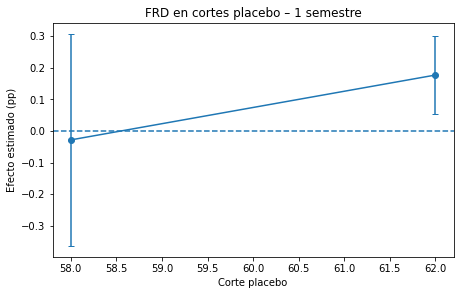

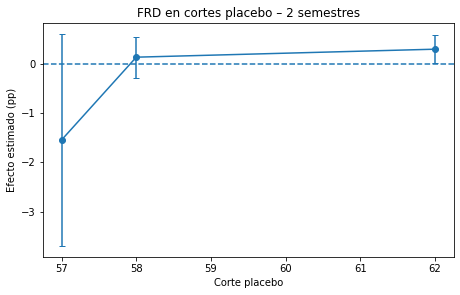

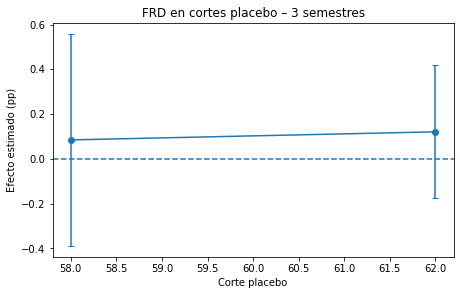

In [22]:
import numpy as np
import pandas as pd

# Copia segura
pt = placebo_tab.copy()

# Elimina filas con errores (si tu construcción los guardó en una columna 'error')
if 'error' in pt.columns:
    pt = pt[pt['error'].isna()].copy()

# Quita casos numéricamente inestables: NaN/Inf o magnitudes astronómicas
for col in ['beta','se','ci_lo','ci_hi','pval']:
    pt = pt[np.isfinite(pt[col])]

# Filtro suave para outliers numéricos (opcional, evita 1e+26)
pt = pt[pt['beta'].abs() < 5]   # 5 p.p. es un umbral razonable para continuidad
pt = pt[pt['se'].abs()   < 5]

# Orden y etiquetas amigables
outcome_map = {
    'continuidad_1': '1 semestre',
    'continuidad_2': '2 semestres',
    'continuidad_3': '3 semestres'
}
pt['Outcome'] = pt['outcome'].map(outcome_map).fillna(pt['outcome'])

# Orden por corte y resultado
pt = pt.sort_values(['cutoff','Outcome']).reset_index(drop=True)

# Versión para reporte (redondeo)
pt_report = pt.copy()
pt_report['Coef'] = pt_report['beta'].round(3)
pt_report['EE']   = pt_report['se'].round(3)
pt_report['IC95%'] = pt_report.apply(lambda r: f"[{r['ci_lo']:.3f}, {r['ci_hi']:.3f}]", axis=1)
pt_report['p-valor'] = pt_report['pval'].map(lambda x: f"{x:.3f}")
pt_report = pt_report[['cutoff','Outcome','Coef','EE','IC95%','p-valor']]

print(pt_report)

import matplotlib.pyplot as plt

# Asegúrate de no usar estilos/colores específicos si estás siguiendo una guía estricta;
# aquí solo trazamos errorbars simples.

for y_label in ['1 semestre','2 semestres','3 semestres']:
    sub = pt[pt['Outcome']==y_label].copy()
    if sub.empty:
        continue
    # Orden por corte ascendente
    sub = sub.sort_values('cutoff')

    x = sub['cutoff'].to_numpy()
    b = sub['beta'].to_numpy()
    se = sub['se'].to_numpy()

    plt.figure(figsize=(6.5, 4.2))
    plt.errorbar(x, b, yerr=1.96*se, fmt='o-', capsize=3)
    plt.axhline(0, linestyle='--')
    plt.xlabel("Corte placebo")
    plt.ylabel("Efecto estimado (pp)")
    plt.title(f"FRD en cortes placebo – {y_label}")
    plt.tight_layout()
    outname = f"fig_placebo_{y_label.replace(' ','_')}.png"
    plt.savefig(outname, bbox_inches="tight")
    plt.show()



# Simulación Monte Carlo

In [ ]:
import numpy as np 
import random
import pandas as pd
from rdrobust import rdrobust

import pandas as pd

# Lee el archivo CSV especificando una codificación alternativa
data = pd.read_csv("C:\\Users\\lisbeth\\OneDrive\\Escritorio\\PUCP\\TESIS\\DATA\\data\\base.csv", encoding='latin1')

# Convertir las columnas de matrícula a booleano para evitar errores con &
data['mat_20_2'] = data['mat_20_2'].astype(bool)
data['mat_21_1'] = data['mat_21_1'].astype(bool)
data['mat_21_2'] = data['mat_21_2'].astype(bool)

# Crear variables de continuidad acumulativa usando &
data['continuidad_1'] = data['mat_20_2']  # Continuidad en 2020-2
data['continuidad_2'] = data['mat_20_2'] & data['mat_21_1']  # Continuidad en 2020-2 y 2021-1
data['continuidad_3'] = data['mat_20_2'] & data['mat_21_1'] & data['mat_21_2']  # Continuidad en los tres semestres

# Convertir las columnas de continuidad acumulativa a 0 y 1 (si es necesario)
data['continuidad_1'] = data['continuidad_1'].astype(int)
data['continuidad_2'] = data['continuidad_2'].astype(int)
data['continuidad_3'] = data['continuidad_3'].astype(int)

import random

# Crear variables de tratamiento y de corte como antes
data['D'] = data['CONDICION'].apply(lambda x: 1 if x == 'SELECCIONADO' else 0)
data['Z'] = data['PUNTAJEFINAL'].apply(lambda x: 1 if x >= 60 else 0)

# Crear columna 'ALEA' para aleatoriedad
data['ALEA'] = [random.randint(0, 500)/100 for _ in range(len(data))]


# Función para calcular Puntaje_RD con aleatoriedad según reglas especificadas
def calcular_puntaje(row, alea):
    if row['PUNTAJEFINAL'] == 60:
        return row['PUNTAJEFINAL'] + alea if row['D'] == 1 else row['PUNTAJEFINAL'] - alea
    else:
        return row['PUNTAJEFINAL'] + alea if random.choice([True, False]) else row['PUNTAJEFINAL'] - alea

# Diccionario para almacenar los resultados de cada nivel de continuidad
resultados_por_nivel = {
    'continuidad_1': {'coeficientes': [], 'errores_estandar': [], 'p_values': [], 't_estadisticos': []},
    'continuidad_2': {'coeficientes': [], 'errores_estandar': [], 'p_values': [], 't_estadisticos': []},
    'continuidad_3': {'coeficientes': [], 'errores_estandar': [], 'p_values': [], 't_estadisticos': []}
}

# Realizar 10000 simulaciones por cada nivel de continuidad
for nivel, columna in {'continuidad_1': 'continuidad_1', 'continuidad_2': 'continuidad_2', 'continuidad_3': 'continuidad_3'}.items():
    for _ in range(10000):
        # Crear columna 'ALEA' para aleatoriedad
        data['ALEA'] = [random.randint(0, 500)/100 for _ in range(len(data))]
        # Generar aleatoriedad para cada estudiante
        #data['ALEA'] = [random.uniform(0, 5) for _ in range(len(data))]

        # Calcular Puntaje_RD usando la función definida
        data['Puntaje_RD'] = data.apply(lambda row: calcular_puntaje(row, row['ALEA']), axis=1)

        # Ejecutar rdrobust con la variable dependiente, el puntaje y el punto de corte para el nivel actual
        est = rdrobust(y=data[columna], x=data['Puntaje_RD'], c=60)

        # Extraer los valores robustos desde el DataFrame est
        robust_coef = est.coef.loc['Robust', 'Coeff']
        robust_se = est.se.loc['Robust']  # Error estándar robusto
        robust_p_value = est.pv.loc['Robust']  # Valor p robusto
        robust_t_stat = est.t.loc['Robust']  # Estadístico t robusto

        # Almacenar los valores en las listas correspondientes del nivel actual
        resultados_por_nivel[nivel]['coeficientes'].append(robust_coef)
        resultados_por_nivel[nivel]['errores_estandar'].append(robust_se)
        resultados_por_nivel[nivel]['p_values'].append(robust_p_value)
        resultados_por_nivel[nivel]['t_estadisticos'].append(robust_t_stat)

# Calcular el promedio de los coeficientes, errores estándar, p-values y t-statistics para cada nivel de continuidad
for nivel, resultados in resultados_por_nivel.items():
    media_coef = np.mean(resultados['coeficientes'])
    media_se = np.mean(resultados['errores_estandar'])
    media_p_value = np.mean(resultados['p_values'])
    media_t_stat = np.mean(resultados['t_estadisticos'])
    intervalo_confianza = np.percentile(resultados['coeficientes'], [2.5, 97.5])

    # Imprimir los resultados por nivel de continuidad
    print(f"\nResultados para {nivel}:")
    print(f"Media de los coeficientes: {media_coef}")
    print(f"Media de los errores estándar: {media_se}")
    print(f"Media de los p-valores: {media_p_value}")
    print(f"Media de los t-estadísticos: {media_t_stat}")
    print(f"Intervalo de confianza (95%): {intervalo_confianza}")

Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the runnin

Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the runnin

Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the runnin

Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the runnin

Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the runnin

...

Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the runnin

Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the runnin

Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the runnin

Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the runnin

Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the runnin